# Book Recommender System on a Medallion Data Lake

**Dataset:** Book-Crossing (Users, Books, Book-Ratings)

Pipeline: raw CSV files → **Bronze** (untouched copy) → **Silver** (cleaned) → **Gold** (model-ready) → item-based collaborative filtering recommender.

In [1]:
import os
import re
import html
import zipfile
import urllib.request
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.neighbors import NearestNeighbors

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)

## Step 1: Set up the data lake and build the Bronze layer

In [2]:
# Data lake folders
for folder in ["raw", "bronze", "silver", "gold"]:
    os.makedirs(folder, exist_ok=True)

DATA_URL = "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip"
zip_path = "raw/book-crossings.zip"

if not os.path.exists(zip_path):
    # the CDN rejects urllib's default user agent (HTTP 403), so send a browser-like one
    req = urllib.request.Request(DATA_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req) as resp, open(zip_path, "wb") as f:
        f.write(resp.read())

with zipfile.ZipFile(zip_path) as z:
    z.extractall("raw")

print(sorted(os.listdir("raw")))

['BX-Book-Ratings.csv', 'BX-Books.csv', 'BX-Users.csv', 'book-crossings.zip']


The files are semicolon-separated and encoded in ISO-8859-1 (latin-1), not UTF-8. Some book titles also contain
backslash-escaped quotes (`\"`). Without `escapechar="\\"` pandas either fails or silently skips 19 book rows,
so the escape character is set to make sure every source row lands in Bronze. No other changes are made here.

In [3]:
READ_OPTS = dict(sep=";", encoding="latin-1", escapechar="\\", low_memory=False)

raw_files = {
    "users": "raw/BX-Users.csv",
    "books": "raw/BX-Books.csv",
    "ratings": "raw/BX-Book-Ratings.csv",
}

ingestion_ts = pd.Timestamp(datetime.now(timezone.utc))

for name, path in raw_files.items():
    df = pd.read_csv(path, **READ_OPTS)
    df["ingestion_timestamp"] = ingestion_ts
    df.to_parquet(f"bronze/{name}.parquet", index=False)
    print(f"{name:8s} -> bronze/{name}.parquet  {df.shape}")

users    -> bronze/users.parquet  (278858, 4)
books    -> bronze/books.parquet  (271379, 9)
ratings  -> bronze/ratings.parquet  (1149780, 4)


In [4]:
# Check: row counts in Bronze match the number of records in the source files
for name, path in raw_files.items():
    with open(path, encoding="latin-1") as f:
        n_lines = sum(1 for _ in f) - 1          # minus the header
    print(f"{name:8s} lines in file (excl. header): {n_lines:>9,}   rows in bronze: {len(pd.read_parquet(f'bronze/{name}.parquet')):>9,}")

users    lines in file (excl. header):   278,859   rows in bronze:   278,858
books    lines in file (excl. header):   271,379   rows in bronze:   271,379
ratings  lines in file (excl. header): 1,149,780   rows in bronze: 1,149,780


Users has one more line than rows because one location value contains a line break inside its quotes
(`"... \n, milan, italy"`), so that record spans two lines. Every record is present.

## Step 2: Explore the Bronze data (EDA)

In [5]:
users_b = pd.read_parquet("bronze/users.parquet")
books_b = pd.read_parquet("bronze/books.parquet")
ratings_b = pd.read_parquet("bronze/ratings.parquet")

for name, df in [("users", users_b), ("books", books_b), ("ratings", ratings_b)]:
    print(f"===== {name}: shape {df.shape}")
    summary = pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum()})
    print(summary, "\n")

===== users: shape (278858, 4)
                                   dtype  missing
User-ID                            int64        0
Location                          object        0
Age                              float64   110762
ingestion_timestamp  datetime64[us, UTC]        0 

===== books: shape (271379, 9)
                                   dtype  missing
ISBN                              object        0
Book-Title                        object        0
Book-Author                       object        2
Year-Of-Publication                int64        0
Publisher                         object        2
Image-URL-S                       object        0
Image-URL-M                       object        0
Image-URL-L                       object        0
ingestion_timestamp  datetime64[us, UTC]        0 

===== ratings: shape (1149780, 4)
                                   dtype  missing
User-ID                            int64        0
ISBN                              object        0


In [6]:
# Duplicates (exact rows and on the key columns)
print("users   exact duplicate rows:", users_b.drop(columns="ingestion_timestamp").duplicated().sum(),
      "| duplicate User-ID:", users_b["User-ID"].duplicated().sum())
print("books   exact duplicate rows:", books_b.drop(columns="ingestion_timestamp").duplicated().sum(),
      "| duplicate ISBN:", books_b["ISBN"].duplicated().sum(),
      "| duplicate ISBN after upper-casing:", books_b["ISBN"].str.strip().str.upper().duplicated().sum())
print("ratings exact duplicate rows:", ratings_b.drop(columns="ingestion_timestamp").duplicated().sum(),
      "| duplicate (User-ID, ISBN):", ratings_b.duplicated(["User-ID", "ISBN"]).sum())

print("\nratings whose ISBN is not in books:", (~ratings_b["ISBN"].isin(books_b["ISBN"])).sum())
print("ratings whose User-ID is not in users:", (~ratings_b["User-ID"].isin(users_b["User-ID"])).sum())
print("titles containing HTML entities (&amp; etc.):", books_b["Book-Title"].str.contains(r"&\w+;").sum())
print("titles with leading/trailing/double spaces:", books_b["Book-Title"].str.contains(r"^\s|\s$|\s{2,}").sum())

users   exact duplicate rows: 0 | duplicate User-ID: 0
books   exact duplicate rows: 0 | duplicate ISBN: 0 | duplicate ISBN after upper-casing: 315
ratings exact duplicate rows: 0 | duplicate (User-ID, ISBN): 0

ratings whose ISBN is not in books: 118605
ratings whose User-ID is not in users: 0
titles containing HTML entities (&amp; etc.): 4908
titles with leading/trailing/double spaces: 2505


- **Shape, types, missing values:** users has 278,858 rows. `Age` is missing for 110,762 of them (about 40%), and `NULL` was read as NaN.
  Books has 271,379 rows, with `Book-Author` and `Publisher` missing twice each. Ratings has 1,149,780 rows with nothing missing.
  There are no exact duplicate rows, but upper-casing ISBNs (`x` → `X`) turns up 315 duplicate books. 118,605 ratings point to
  ISBNs that don't exist in books, and 4,908 titles contain HTML entities (`&amp;`) while 2,505 have stray spaces.
  → In Silver: rename columns to snake_case, normalise ISBNs and de-duplicate, drop ratings with no matching book or user,
  and clean the text (unescape entities, strip spaces).

Book-Rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610

ratings equal to 0: 716,109 of 1,149,780 (62.3%)


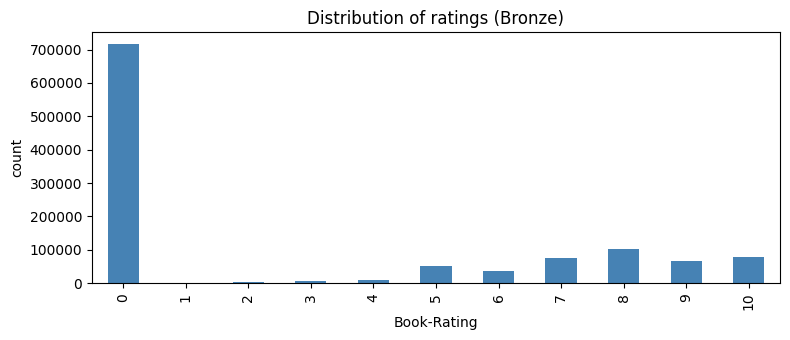

In [7]:
rating_counts = ratings_b["Book-Rating"].value_counts().sort_index()
print(rating_counts.to_string())
print(f"\nratings equal to 0: {rating_counts[0]:,} of {len(ratings_b):,} ({rating_counts[0] / len(ratings_b):.1%})")

fig, ax = plt.subplots(figsize=(8, 3.5))
rating_counts.plot.bar(ax=ax, color="steelblue")
ax.set_xlabel("Book-Rating"); ax.set_ylabel("count"); ax.set_title("Distribution of ratings (Bronze)")
plt.tight_layout(); plt.show()

- **Ratings distribution:** 716,109 of 1,149,780 ratings (62.3%) are 0, which means implicit interaction, not a score.
  The explicit ratings (1–10) lean high, peaking at 8 with few below 5. → In Silver: drop the 0s and keep only ratings from 1 to 10.

Age summary:
 count    168096.00
mean         34.75
std          14.43
min           0.00
25%          24.00
50%          32.00
75%          44.00
max         244.00

age < 5: 882   age > 100: 366   missing: 110,762

Year-Of-Publication summary:
 count    271379.00
mean       1959.76
std         258.01
min           0.00
25%        1989.00
50%        1995.00
75%        2000.00
max        2050.00

year == 0: 4,619   year > 2026 (future): 11
future years found: [2030, 2037, 2038, 2050]

earliest non-zero years:
      ISBN                       Book-Title  Year-Of-Publication
9643112136 Dalan-i bihisht (Dastan-i Irani)                 1378
964442011X                     Tasht-i khun                 1376


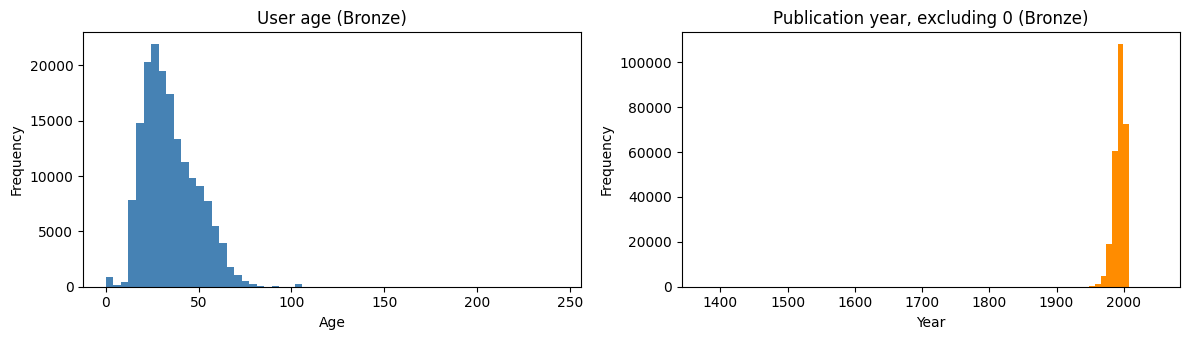

In [8]:
print("Age summary:\n", users_b["Age"].describe().round(2).to_string())
print(f"\nage < 5: {(users_b['Age'] < 5).sum()}   age > 100: {(users_b['Age'] > 100).sum()}   missing: {users_b['Age'].isna().sum():,}")

year = books_b["Year-Of-Publication"]
current_year = datetime.now().year
print("\nYear-Of-Publication summary:\n", year.describe().round(2).to_string())
print(f"\nyear == 0: {(year == 0).sum():,}   year > {current_year} (future): {(year > current_year).sum()}")
print("future years found:", sorted(year[year > current_year].unique().tolist()))
print("\nearliest non-zero years:")
print(books_b.loc[(year > 0) & (year < 1500), ["ISBN", "Book-Title", "Year-Of-Publication"]].to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
users_b["Age"].dropna().plot.hist(bins=60, ax=axes[0], color="steelblue")
axes[0].set_title("User age (Bronze)"); axes[0].set_xlabel("Age")
year[year > 0].plot.hist(bins=80, ax=axes[1], color="darkorange")
axes[1].set_title("Publication year, excluding 0 (Bronze)"); axes[1].set_xlabel("Year")
plt.tight_layout(); plt.show()

- **Ages and publication years:** ages run from 0 to 244 (median 32), with 882 users under 5 and 366 over 100, which can't be real.
  Publication years include 4,619 zeros and 11 years in the future (2030, 2037, 2038, 2050). → In Silver: set ages outside 5–100 to null
  and fill with the median age, and set year 0 and future years to null. Two books dated 1376/1378 are Iranian titles (ISBN prefix 964) using the
  Persian calendar, so those are valid dates and are kept.

explicit ratings per user: n=77,805  median=1  mean=5.57  max=8,524
   exactly 1 rating: 58.3%   >=5: 14,220   >=10: 7,334   >=20: 3,704
explicit ratings per book: n=185,973  median=1  mean=2.33  max=707
   exactly 1 rating: 69.7%   >=5: 14,535   >=10: 5,645   >=20: 2,179


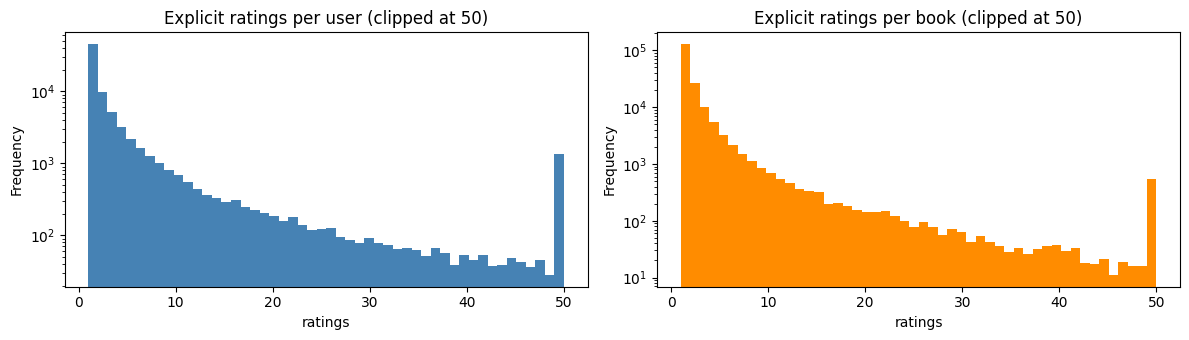

In [9]:
explicit_b = ratings_b[ratings_b["Book-Rating"] > 0]
per_user = explicit_b.groupby("User-ID").size()
per_book = explicit_b.groupby("ISBN").size()

def describe_counts(s, label):
    print(f"{label}: n={len(s):,}  median={s.median():.0f}  mean={s.mean():.2f}  max={s.max():,}")
    print(f"   exactly 1 rating: {(s == 1).mean():.1%}   >=5: {(s >= 5).sum():,}   >=10: {(s >= 10).sum():,}   >=20: {(s >= 20).sum():,}")

describe_counts(per_user, "explicit ratings per user")
describe_counts(per_book, "explicit ratings per book")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
per_user.clip(upper=50).plot.hist(bins=50, ax=axes[0], log=True, color="steelblue")
axes[0].set_title("Explicit ratings per user (clipped at 50)"); axes[0].set_xlabel("ratings")
per_book.clip(upper=50).plot.hist(bins=50, ax=axes[1], log=True, color="darkorange")
axes[1].set_title("Explicit ratings per book (clipped at 50)"); axes[1].set_xlabel("ratings")
plt.tight_layout(); plt.show()

- **Ratings per user and per book:** both have a long tail. Among explicit ratings, the median user and the median book each have just 1 rating;
  58.3% of users rated only one book and 69.7% of books were rated only once. Only 7,334 users and 5,645 books have 10 or more.
  → In Silver: keep only users and books above a minimum rating count, since an item with one rating has no overlap to compute similarity from.

In [10]:
def sparsity(df, user_col, item_col):
    n_users, n_items = df[user_col].nunique(), df[item_col].nunique()
    filled = len(df) / (n_users * n_items)
    return n_users, n_items, filled

for label, df in [("all ratings", ratings_b), ("explicit ratings (1-10)", explicit_b)]:
    nu, ni, filled = sparsity(df, "User-ID", "ISBN")
    print(f"{label:24s} users={nu:,}  books={ni:,}  possible pairs={nu * ni:,}  "
          f"filled={filled:.5%}  sparsity={1 - filled:.5%}")

all ratings              users=105,283  books=340,556  possible pairs=35,854,757,348  filled=0.00321%  sparsity=99.99679%
explicit ratings (1-10)  users=77,805  books=185,973  possible pairs=14,469,629,265  filled=0.00300%  sparsity=99.99700%


- **Matrix sparsity:** only about 0.0032% of the ~35.9 billion possible user-book pairs have a rating (0.0030% for explicit
  ratings), so the matrix is about 99.997% empty. → In Silver/Gold: filter out low-activity users and books to make it denser,
  and store the matrix as a sparse matrix.

## Step 3: Clean the data and build the Silver layer

In [11]:
users = users_b.drop(columns="ingestion_timestamp").rename(columns={
    "User-ID": "user_id", "Location": "location", "Age": "age"})
books = books_b.drop(columns="ingestion_timestamp").rename(columns={
    "ISBN": "isbn", "Book-Title": "title", "Book-Author": "author",
    "Year-Of-Publication": "year", "Publisher": "publisher",
    "Image-URL-S": "image_url_s", "Image-URL-M": "image_url_m", "Image-URL-L": "image_url_l"})
ratings = ratings_b.drop(columns="ingestion_timestamp").rename(columns={
    "User-ID": "user_id", "ISBN": "isbn", "Book-Rating": "rating"})

log = []   # (step, table, rows after)
def track(step, table, df):
    log.append((step, table, len(df)))

for t, df in [("users", users), ("books", books), ("ratings", ratings)]:
    track("start", t, df)

### 3.1 Clean text columns
Every text column has extra whitespace stripped (leading, trailing, and repeated internal spaces) and HTML entities decoded (`&amp;` → `&`).
Values that were UTF-8 but got stored as latin-1 are repaired (`ExupÃ©ry` → `Exupéry`, and double-encoded ones like `KÃ?Â¤stner` → `Kästner`).
Case is standardised by column type:
- ISBN → UPPER CASE, so `x` and `X` check digits match
- title, author, publisher → Title Case, with apostrophes and ordinals fixed (`Sorcerer's` and `1st`, not `Sorcerer'S` and `1St`)
- author initials get consistent spacing (`J.R.R.` → `J. R. R.`)
- location fields → lower case

The three image-URL columns aren't needed for recommending, so they're dropped.

In [12]:
def fix_mojibake(x):
    # Some values are UTF-8 text that was stored as latin-1, e.g. "ExupÃ©ry" -> "Exupéry".
    # Others were encoded twice and one byte got replaced by '?', e.g. "KÃ?Â¤stner" -> "Kästner";
    # the last byte still identifies the letter (0xC3 + byte), so it can be rebuilt.
    if "Ã" not in x and "Â" not in x:
        return x
    x = re.sub(r"Ã\?Â([\x80-\xbf])", lambda m: bytes([0xC3, ord(m.group(1))]).decode("utf-8"), x)
    try:
        return x.encode("latin-1").decode("utf-8")
    except (UnicodeEncodeError, UnicodeDecodeError):
        return x

def clean_text(s):
    s = s.astype("string").map(lambda x: fix_mojibake(html.unescape(x)) if isinstance(x, str) else x)
    s = s.str.replace(r"\s+", " ", regex=True).str.strip()
    return s.replace("", pd.NA)

def to_title_case(s):
    s = s.str.title()
    # str.title() turns "sorcerer's" into "Sorcerer'S" and "1st" into "1St"; undo those
    s = s.str.replace(r"'([A-Z]{1,2})\b", lambda m: "'" + m.group(1).lower(), regex=True)
    return s.str.replace(r"(\d)([A-Z])", lambda m: m.group(1) + m.group(2).lower(), regex=True)

books = books.drop(columns=["image_url_s", "image_url_m", "image_url_l"])
books["isbn"] = clean_text(books["isbn"]).str.upper()
for col in ["title", "author", "publisher"]:
    books[col] = to_title_case(clean_text(books[col]))
# same spacing for initials so "J.R.R. Tolkien" and "J. R. R. Tolkien" become one author
books["author"] = books["author"].str.replace(r"\.(?=[A-Za-z])", ". ", regex=True)

print("unique authors before:", books_b["Book-Author"].nunique(), " after:", books["author"].nunique())
had = sum(books_b[c].str.contains("Ã|Â", na=False).sum() for c in ["Book-Title", "Book-Author", "Publisher"])
left = sum(books[c].str.contains("Ã|Â", na=False).sum() for c in ["title", "author", "publisher"])
print(f"values with broken encoding: {had:,} before, {left:,} after (these lost two bytes and can't be recovered)")

ratings["isbn"] = clean_text(ratings["isbn"]).str.upper()
users["location"] = clean_text(users["location"]).str.lower()

books.head()

unique authors before: 102026  after: 98459
values with broken encoding: 10,516 before, 671 after (these lost two bytes and can't be recovered)


,isbn,title,author,year,publisher
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press
1,0002005018,Clara Callan,Richard Bruce Wright,2001,Harperflamingo Canada
2,0060973129,Decision In Normandy,Carlo D'Este,1991,Harperperennial
3,0374157065,Flu: The Story Of The Great Influenza Pandemic Of 1918 A...,Gina Bari Kolata,1999,Farrar Straus Giroux
4,0393045218,The Mummies Of Urumchi,E. J. W. Barber,1999,W. W. Norton & Company


### 3.2 Remove duplicate rows
Exact duplicates go first, then duplicates on each table's key: `user_id` for users, `isbn` for books (repeats
come from ISBNs that only differed in the case of `x`), and `(user_id, isbn)` for ratings.

In [13]:
before = (len(users), len(books), len(ratings))

users = users.drop_duplicates().drop_duplicates(subset="user_id", keep="first")
books = books.drop_duplicates().drop_duplicates(subset="isbn", keep="first")
ratings = ratings.drop_duplicates().drop_duplicates(subset=["user_id", "isbn"], keep="last")

print(f"users   removed: {before[0] - len(users):,}")
print(f"books   removed: {before[1] - len(books):,}")
print(f"ratings removed: {before[2] - len(ratings):,}")
for t, df in [("users", users), ("books", books), ("ratings", ratings)]:
    track("remove duplicates", t, df)

users   removed: 0
books   removed: 315
ratings removed: 0


### 3.3 Remove ratings of 0 (keep 1–10)

In [14]:
n0 = len(ratings)
ratings = ratings[ratings["rating"].between(1, 10)].copy()
print(f"removed {n0 - len(ratings):,} ratings outside 1-10, {len(ratings):,} explicit ratings remain")
print("rating range now:", ratings["rating"].min(), "-", ratings["rating"].max())
track("drop rating 0", "ratings", ratings)

removed 716,109 ratings outside 1-10, 433,671 explicit ratings remain
rating range now: 1 - 10


### 3.4 Fix user ages
Ages below 5 or above 100 are set to null. All nulls are then filled with the median of the remaining valid ages.

In [15]:
invalid_age = (users["age"] < 5) | (users["age"] > 100)
print(f"ages set to null (outside 5-100): {invalid_age.sum():,}")
users.loc[invalid_age, "age"] = np.nan

median_age = users["age"].median()
print(f"nulls to fill: {users['age'].isna().sum():,}   median age used: {median_age}")
users["age"] = users["age"].fillna(median_age).astype(int)

print(users["age"].describe().round(2).to_string())

ages set to null (outside 5-100): 1,248
nulls to fill: 112,010   median age used: 32.0
count    278858.00
mean         33.64
std          10.63
min           5.00
25%          29.00
50%          32.00
75%          35.00
max         100.00


### 3.5 Split `location` into city, state and country
Most locations have the form `city, state, country`. The rule used:
- 1 part → city only
- 2 parts → city and country
- 3 or more parts → the first part is the city, the last is the country, and everything in between is the state
  (for example `kidderminster, worcestershire, england, united kingdom` → state `worcestershire, england`)

Placeholders such as empty strings, `n/a` or `?` become null.

In [16]:
PLACEHOLDERS = {"", "n/a", "na", "n.a.", "none", "null", "unknown", "?", "-", ".", ",", "x", "xxx"}

def split_location(loc):
    if not isinstance(loc, str):
        return (None, None, None)
    parts = [p.strip() for p in loc.split(",")]
    parts = [None if p in PLACEHOLDERS else p for p in parts]
    if len(parts) == 1:
        return (parts[0], None, None)
    if len(parts) == 2:
        return (parts[0], None, parts[1])
    middle = [p for p in parts[1:-1] if p]
    return (parts[0], ", ".join(middle) if middle else None, parts[-1])

users[["city", "state", "country"]] = pd.DataFrame(
    users["location"].map(split_location).tolist(), index=users.index)

print("missing after split:\n", users[["city", "state", "country"]].isna().sum().to_string())
print("\ntop countries:\n", users["country"].value_counts().head(10).to_string())
users.head()

missing after split:
 city         672
state      16433
country     4610

top countries:
 country
usa               139712
canada             21658
united kingdom     18556
germany            17073
spain              13258
australia          11785
italy              11271
france              3487
portugal            3390
new zealand         3120


,user_id,location,age,city,state,country
0,1,"nyc, new york, usa",32,nyc,new york,usa
1,2,"stockton, california, usa",18,stockton,california,usa
2,3,"moscow, yukon territory, russia",32,moscow,yukon territory,russia
3,4,"porto, v.n.gaia, portugal",17,porto,v.n.gaia,portugal
4,5,"farnborough, hants, united kingdom",32,farnborough,hants,united kingdom


### 3.6 Fix publication years
Year 0 and any year after the current year become null. The column uses pandas' nullable integer type so years
stay whole numbers instead of turning into floats.

In [17]:
current_year = datetime.now().year
bad_year = (books["year"] == 0) | (books["year"] > current_year)
print(f"years set to null: {bad_year.sum():,}  (0: {(books['year'] == 0).sum():,}, future: {(books['year'] > current_year).sum()})")
books["year"] = books["year"].astype("Int64").mask(bad_year)
print("valid year range:", books["year"].min(), "-", books["year"].max())

years set to null: 4,623  (0: 4,612, future: 11)
valid year range: 1376 - 2026


### 3.7 Keep only ratings whose book and user exist

In [18]:
n0 = len(ratings)
ratings = ratings[ratings["isbn"].isin(books["isbn"]) & ratings["user_id"].isin(users["user_id"])].copy()
print(f"removed {n0 - len(ratings):,} ratings with no matching book/user, {len(ratings):,} remain")
print(f"users with at least one rating: {ratings['user_id'].nunique():,}   books with at least one rating: {ratings['isbn'].nunique():,}")
track("referential integrity", "ratings", ratings)

removed 49,818 ratings with no matching book/user, 383,853 remain
users with at least one rating: 68,092   books with at least one rating: 149,723


### 3.8 Minimum number of ratings per user and per book

Removing users can push a book below the threshold and the other way round, so the filter repeats until nothing more changes.
The table compares several thresholds on the cleaned ratings:

In [19]:
def filter_min_ratings(df, min_user, min_book):
    while True:
        n = len(df)
        df = df[df.groupby("user_id")["isbn"].transform("size") >= min_user]
        df = df[df.groupby("isbn")["user_id"].transform("size") >= min_book]
        if len(df) == n:
            return df

rows = []
for mu, mb in [(1, 1), (5, 5), (5, 10), (10, 10), (10, 15), (15, 15)]:
    d = filter_min_ratings(ratings, mu, mb)
    nu, nb = d["user_id"].nunique(), d["isbn"].nunique()
    rows.append({"min_user": mu, "min_book": mb, "ratings": len(d), "users": nu, "books": nb,
                 "density_%": round(100 * len(d) / (nu * nb), 4) if nu and nb else 0.0,
                 "median_ratings_per_user": d.groupby("user_id").size().median() if len(d) else 0})
pd.DataFrame(rows)

,min_user,min_book,ratings,users,books,density_%,median_ratings_per_user
0,1,1,383853,68092,149723,0.0038,1.0
1,5,5,115332,6858,9092,0.1850,9.0
2,5,10,69346,4749,3060,0.4772,9.0
3,10,10,41469,1820,2030,1.1224,16.0
4,10,15,18839,969,709,2.7421,15.0
5,15,15,0,0,0,0.0000,0.0


**Chosen threshold: at least 10 ratings per user and at least 10 ratings per book.**

The EDA showed that the median user and the median book each have only one explicit rating. Cosine similarity between two books
depends on users who rated both, so books and users with one or two ratings add noise and almost no overlap. At 10/10 the matrix
goes from 0.0038% filled to 1.12% filled (about 300 times denser), and each remaining user has a median of 16 ratings to build a profile from.
2,030 books are left, which is still enough variety to recommend from. At 5/5 there are more books but the matrix is
6× sparser. Raising the book threshold to 15 leaves only 709 books, and at 15/15 the repeated filtering removes everything.

In [20]:
MIN_USER_RATINGS = 10
MIN_BOOK_RATINGS = 10

ratings = filter_min_ratings(ratings, MIN_USER_RATINGS, MIN_BOOK_RATINGS).reset_index(drop=True)
track("min ratings filter", "ratings", ratings)

# keep only users and books that still have ratings
users = users[users["user_id"].isin(ratings["user_id"])].reset_index(drop=True)
books = books[books["isbn"].isin(ratings["isbn"])].reset_index(drop=True)
track("min ratings filter", "users", users)
track("min ratings filter", "books", books)

print(f"ratings: {len(ratings):,}   users: {len(users):,}   books: {len(books):,}")
print("min ratings per user:", ratings.groupby("user_id").size().min(),
      "  min ratings per book:", ratings.groupby("isbn").size().min())

ratings: 41,469   users: 1,820   books: 2,030
min ratings per user: 10   min ratings per book: 10


In [21]:
# Final checks before writing Silver
assert ratings["rating"].between(1, 10).all()
assert users["age"].between(5, 100).all()
assert not users["user_id"].duplicated().any()
assert not books["isbn"].duplicated().any()
assert not ratings.duplicated(["user_id", "isbn"]).any()
assert ratings["isbn"].isin(books["isbn"]).all() and ratings["user_id"].isin(users["user_id"]).all()
assert not any(c.startswith("image_url") for c in books.columns)

users.to_parquet("silver/users.parquet", index=False)
books.to_parquet("silver/books.parquet", index=False)
ratings.to_parquet("silver/ratings.parquet", index=False)

pd.DataFrame(log, columns=["step", "table", "rows_after"])

,step,table,rows_after
0,start,users,278858
1,start,books,271379
2,start,ratings,1149780
3,remove duplicates,users,278858
4,remove duplicates,books,271064
5,remove duplicates,ratings,1149780
6,drop rating 0,ratings,433671
7,referential integrity,ratings,383853
8,min ratings filter,ratings,41469
9,min ratings filter,users,1820


## Step 4: Build the Gold layer

In [22]:
users_s = pd.read_parquet("silver/users.parquet")
books_s = pd.read_parquet("silver/books.parquet")
ratings_s = pd.read_parquet("silver/ratings.parquet")

# Integer indices for the matrix
user_ids = np.sort(ratings_s["user_id"].unique())
isbns = np.sort(ratings_s["isbn"].unique())
user_to_idx = {u: i for i, u in enumerate(user_ids)}
isbn_to_idx = {b: i for i, b in enumerate(isbns)}

row = ratings_s["user_id"].map(user_to_idx).to_numpy()
col = ratings_s["isbn"].map(isbn_to_idx).to_numpy()
vals = ratings_s["rating"].to_numpy(dtype=np.float32)

# user x book sparse rating matrix
rating_matrix = sparse.csr_matrix((vals, (row, col)), shape=(len(user_ids), len(isbns)))
sparse.save_npz("gold/user_book_matrix.npz", rating_matrix)
pd.DataFrame({"user_idx": np.arange(len(user_ids)), "user_id": user_ids}).to_parquet("gold/user_index.parquet", index=False)

print("matrix shape (users x books):", rating_matrix.shape)
print(f"stored ratings: {rating_matrix.nnz:,}   density: {rating_matrix.nnz / np.prod(rating_matrix.shape):.4%}")
print(f"dense size would be {np.prod(rating_matrix.shape) * 4 / 1e6:.1f} MB, sparse size is "
      f"{(rating_matrix.data.nbytes + rating_matrix.indices.nbytes + rating_matrix.indptr.nbytes) / 1e6:.2f} MB")

matrix shape (users x books): (1820, 2030)
stored ratings: 41,469   density: 1.1224%
dense size would be 14.8 MB, sparse size is 0.34 MB


In [23]:
# Book lookup table: book index in the matrix -> isbn, title, author
book_lookup = (pd.DataFrame({"book_idx": np.arange(len(isbns)), "isbn": isbns})
               .merge(books_s[["isbn", "title", "author", "year", "publisher"]], on="isbn", how="left"))
book_lookup.to_parquet("gold/book_lookup.parquet", index=False)
book_lookup.head()

,book_idx,isbn,title,author,year,publisher
0,0,0020199600,Great Gatsby (Reissue),F. Scott Fitzgerald,1988,Scribner Paper Fiction
1,1,0020442203,"Lion, The Witch And The Wardrobe",C. S. Lewis,1970,Macmillan Publishing Company.
2,2,002542730X,Politically Correct Bedtime Stories: Modern Tales For Ou...,James Finn Garner,1994,John Wiley & Sons Inc
3,3,0028604199,Once Upon A More Enlightened Time: More Politically Corr...,James Finn Garner,1995,Macmillan Publishing Company.
4,4,0060002050,On A Wicked Dawn (Cynster Novels),Stephanie Laurens,2002,Avon Books


In [24]:
# User-level and book-level aggregates
user_stats = (ratings_s.groupby("user_id")["rating"]
              .agg(avg_rating="mean", num_ratings="size").round({"avg_rating": 3}).reset_index()
              .merge(users_s[["user_id", "age", "city", "state", "country"]], on="user_id", how="left"))

book_stats = (ratings_s.groupby("isbn")["rating"]
              .agg(avg_rating="mean", num_ratings="size").round({"avg_rating": 3}).reset_index()
              .merge(book_lookup[["isbn", "title", "author"]], on="isbn", how="left"))

user_stats.to_parquet("gold/user_stats.parquet", index=False)
book_stats.to_parquet("gold/book_stats.parquet", index=False)

print("Most-rated books:")
display(book_stats.sort_values("num_ratings", ascending=False).head(10))
print("Most active users:")
display(user_stats.sort_values("num_ratings", ascending=False).head(5))

Most-rated books:


,isbn,avg_rating,num_ratings,title,author
281,0316666343,8.238,223,The Lovely Bones: A Novel,Alice Sebold
662,0385504209,8.610,177,The Da Vinci Code,Dan Brown
205,0312195516,8.492,132,The Red Tent (Bestselling Backlist),Anita Diamant
176,0142001740,8.664,125,The Secret Life Of Bees,Sue Monk Kidd
1520,059035342X,9.042,119,Harry Potter And The Sorcerer's Stone (Harry Potter (Pap...,J. K. Rowling
1100,0446672211,8.296,115,Where The Heart Is (Oprah's Book Club (Paperback)),Billie Letts
44,0060928336,8.124,113,Divine Secrets Of The Ya-Ya Sisterhood: A Novel,Rebecca Wells
869,043935806X,9.072,111,Harry Potter And The Order Of The Phoenix (Book 5),J. K. Rowling
332,0345337662,7.714,105,Interview With The Vampire,Anne Rice
275,0316601950,7.792,101,The Pilot's Wife : A Novel,Anita Shreve


Most active users:


,user_id,avg_rating,num_ratings,age,city,state,country
59,11676,7.705,954,32,None,None,None
86,16795,7.818,242,47,mechanicsville,maryland,usa
607,95359,8.005,195,33,charleston,west virginia,usa
668,104636,8.733,187,32,youngstown,ohio,usa
737,114368,6.784,176,33,mechanicsville,maryland,usa


In [25]:
# Data lake contents
for layer in ["bronze", "silver", "gold"]:
    for f in sorted(os.listdir(layer)):
        print(f"{layer}/{f:28s} {os.path.getsize(os.path.join(layer, f)) / 1e6:8.2f} MB")

bronze/books.parquet                   21.67 MB
bronze/ratings.parquet                  9.81 MB
bronze/users.parquet                    4.35 MB
silver/books.parquet                    0.08 MB
silver/ratings.parquet                  0.11 MB
silver/users.parquet                    0.05 MB
gold/book_lookup.parquet              0.09 MB
gold/book_stats.parquet               0.08 MB
gold/user_book_matrix.npz             0.10 MB
gold/user_index.parquet               0.02 MB
gold/user_stats.parquet               0.04 MB


## Step 5: Item-based collaborative filtering

### 5.1 Load the Gold matrix and transpose it to book × user

In [26]:
user_book = sparse.load_npz("gold/user_book_matrix.npz")
lookup = pd.read_parquet("gold/book_lookup.parquet")
user_index = pd.read_parquet("gold/user_index.parquet")

book_user = user_book.T.tocsr()          # rows = books, columns = users
print("book x user matrix:", book_user.shape)

uid_to_idx = dict(zip(user_index["user_id"], user_index["user_idx"]))
idx_to_title = lookup.set_index("book_idx")["title"]
idx_to_author = lookup.set_index("book_idx")["author"]

# The same book often appears under several ISBNs (hardcover, paperback, reissue) with slightly
# different titles, e.g. "The Lovely Bones" and "The Lovely Bones: A Novel", or
# "P Is For Peril" and "P Is For Peril (Kinsey Millhone Mysteries (Hardcover))".
# A base title (lower case, cut at the first '(' or ':', no leading article, letters/digits only)
# is used to treat these as one book.
def base_title(t):
    t = re.split(r"[(:]", t.lower())[0]
    t = re.sub(r"[^a-z0-9 ]", "", t)
    t = re.sub(r"^(the|a|an) ", "", t.strip())
    return re.sub(r"\s+", " ", t).strip()

idx_to_base = lookup.set_index("book_idx")["title"].map(base_title)

book x user matrix: (2030, 1820)


### 5.2 Cosine similarity between books
`NearestNeighbors` with the cosine metric works directly on the sparse matrix and returns the cosine *distance*,
so similarity = 1 − distance. The neighbours of every book are computed once up front and reused.

In [27]:
K_NEIGHBORS = 30

knn = NearestNeighbors(metric="cosine", algorithm="brute", n_neighbors=K_NEIGHBORS + 1)
knn.fit(book_user)

distances, indices = knn.kneighbors(book_user)
similarities = 1 - distances

# drop each book's match with itself
self_match = indices == np.arange(book_user.shape[0])[:, None]
neighbor_idx = np.where(self_match, -1, indices)
neighbor_sim = np.where(self_match, 0.0, similarities)

print("neighbour table:", neighbor_idx.shape)

neighbour table: (2030, 31)


### 5.3 Similar books for a title
Title matching ignores case, and titles that start with the query also count as a match. Several editions can share a title;
in that case the most-rated one is used as the query. Other editions of the query book are removed from the results,
and each book appears only once.

In [28]:
ratings_per_book = np.asarray((book_user > 0).sum(axis=1)).ravel()

def find_book(title):
    t = title.strip().lower()
    titles = lookup["title"].str.lower()
    matches = lookup[titles.str.startswith(t, na=False)]
    if matches.empty:
        matches = lookup[titles.str.contains(t, regex=False, na=False)]
    if matches.empty:
        return None
    return int(matches.loc[matches["book_idx"].map(lambda i: ratings_per_book[i]).idxmax(), "book_idx"])

def similar_books(title, n=10):
    b = find_book(title)
    if b is None:
        print(f"No book found matching '{title}'")
        return pd.DataFrame(columns=["title", "author", "similarity"])
    rows, seen = [], {idx_to_base[b]}
    for j, s in zip(neighbor_idx[b], neighbor_sim[b]):
        if j < 0 or s <= 0:
            continue
        t = idx_to_title[j]
        if idx_to_base[j] in seen:
            continue
        seen.add(idx_to_base[j])
        rows.append({"title": t, "author": idx_to_author[j], "similarity": round(float(s), 4)})
        if len(rows) == n:
            break
    print(f"Books similar to: {idx_to_title[b]} ({idx_to_author[b]})")
    return pd.DataFrame(rows, index=range(1, len(rows) + 1))

In [29]:
similar_books("Harry Potter and the Sorcerer's Stone")

Books similar to: Harry Potter And The Sorcerer's Stone (Harry Potter (Paperback)) (J. K. Rowling)


,title,author,similarity
1,Harry Potter And The Chamber Of Secrets (Book 2),J. K. Rowling,0.4110
2,Harry Potter And The Prisoner Of Azkaban (Book 3),J. K. Rowling,0.3156
3,Harry Potter And The Goblet Of Fire (Book 4),J. K. Rowling,0.2541
4,Harry Potter And The Order Of The Phoenix (Book 5),J. K. Rowling,0.2429
5,Fried Green Tomatoes At The Whistle Stop Cafe,Fannie Flagg,0.1885
6,Love Story,Erich Segal,0.1696
7,Anne Of Green Gables (Anne Of Green Gables Novels (Paper...,L. M. Montgomery,0.1633
8,Anne Of Ingleside (Anne Of Green Gables Novels (Paperback)),L. M. Montgomery,0.1561
9,Like Water For Chocolate: A Novel In Monthly Installment...,Laura Esquivel,0.1551
10,"Blood Of The Fold (Sword Of Truth, Book 3)",Terry Goodkind,0.1542


In [30]:
similar_books("The Lovely Bones")

Books similar to: The Lovely Bones: A Novel (Alice Sebold)


,title,author,similarity
1,Where The Heart Is (Oprah's Book Club (Paperback)),Billie Letts,0.2192
2,Lucky : A Memoir,Alice Sebold,0.2180
3,The Da Vinci Code,Dan Brown,0.1783
4,The Pilot's Wife : A Novel,Anita Shreve,0.1763
5,Good In Bed,Jennifer Weiner,0.1758
6,Nights In Rodanthe,Nicholas Sparks,0.1702
7,The Pact: A Love Story,Jodi Picoult,0.1682
8,The Lake House,James Patterson,0.1662
9,White Oleander : A Novel (Oprah's Book Club),Janet Fitch,0.1542
10,The Book Of Ruth (Oprah's Book Club (Paperback)),Jane Hamilton,0.1534


### 5.4 `recommend(user_id, n=10)`
1. Read the user's ratings from the matrix. "Rated highly" means a rating of 8 or more; if the user has none that high, their ratings at or above their own average are used.
2. For each highly rated book, take its nearest neighbours and add `similarity × user's rating` to each candidate's score. Books that are close to several liked books get higher scores.
3. Remove every book the user has already rated, including other editions of it (same base title).
4. Return the top n titles, each title only once.

In [31]:
HIGH_RATING = 8

def liked_books(user_id):
    u = uid_to_idx[user_id]
    row = user_book.getrow(u)
    rated = pd.Series(row.data, index=row.indices)
    liked = rated[rated >= HIGH_RATING]
    if liked.empty:
        liked = rated[rated >= rated.mean()]
    return rated, liked.sort_values(ascending=False)

def recommend(user_id, n=10):
    if user_id not in uid_to_idx:
        raise ValueError(f"user {user_id} is not in the Gold rating matrix")
    rated, liked = liked_books(user_id)
    read_books = {idx_to_base[i] for i in rated.index}     # every book the user has rated, any edition

    scores = {}
    for b, r in liked.items():
        for j, s in zip(neighbor_idx[b], neighbor_sim[b]):
            if j < 0 or s <= 0 or j in rated.index:
                continue
            scores[j] = scores.get(j, 0.0) + s * r

    recs, seen = [], set(read_books)
    for j, score in sorted(scores.items(), key=lambda kv: kv[1], reverse=True):
        t = idx_to_title[j]
        if idx_to_base[j] in seen:
            continue
        seen.add(idx_to_base[j])
        recs.append({"title": t, "author": idx_to_author[j], "score": round(score, 3)})
        if len(recs) == n:
            break
    return pd.DataFrame(recs, index=range(1, len(recs) + 1))

## Step 6: Demo and sanity check

In [32]:
def show_user(user_id, n=10):
    rated, liked = liked_books(user_id)
    stats = user_stats.set_index("user_id").loc[user_id]
    print(f"User {user_id}: {int(stats.num_ratings)} ratings, average {stats.avg_rating:.2f}, "
          f"{len(liked)} rated highly | {stats.city}, {stats.country}, age {stats.age}")

    liked_df = pd.DataFrame({
        "rated highly": [f"{idx_to_title[i]} ({int(r)})" for i, r in liked.items()][:n]})
    recs = recommend(user_id, n)
    rec_df = pd.DataFrame({"recommended": [f"{t} - {a}" for t, a in zip(recs["title"], recs["author"])]})

    side_by_side = pd.concat([liked_df.reset_index(drop=True), rec_df.reset_index(drop=True)], axis=1).fillna("")
    side_by_side.index = range(1, len(side_by_side) + 1)
    with pd.option_context("display.max_colwidth", 70):
        display(side_by_side)

In [33]:
DEMO_USERS = [115572, 254206, 162052]

show_user(DEMO_USERS[0])

User 115572: 31 ratings, average 9.06, 28 rated highly | darlington, usa, age 23


,rated highly,recommended
1,Harry Potter And The Chamber Of Secrets (Book 2) (10),Anne's House Of Dreams - L. M. Montgomery
2,Harry Potter And The Goblet Of Fire (Book 4) (10),The Voyage Of The Dawn Treader (Rack) (Narnia) - C. S. Lewis
3,Bridge To Terabithia (10),The Silver Chair - C. S. Lewis
4,The Secret Garden (10),Rilla Of Ingleside (Anne Of Green Gables Novels (Paperback)) - L. ...
5,Harry Potter And The Sorcerer's Stone (Book 1) (10),Anne Of The Island - Lucy Maud Montgomery
6,Rainbow Valley (Anne Of Green Gables Novels (Paperback)) (10),Anne Of Avonlea (Anne Of Green Gables Novels (Paperback)) - L. M. ...
7,Anne Of Windy Poplars (Anne Of Green Gables Novels (Paperback)) (10),The Magician's Nephew (Rack) (Narnia) - C. S. Lewis
8,Anne Of Ingleside (Anne Of Green Gables Novels (Paperback)) (10),Anne Of Green Gables (Anne Of Green Gables Novels (Paperback)) - L...
9,The Red Tent (Bestselling Backlist) (10),Farmer Boy (Little House) - Laura Ingalls Wilder
10,Interview With The Vampire (10),On The Banks Of Plum Creek - Laura Ingalls Wilder


In [34]:
show_user(DEMO_USERS[1])

User 254206: 38 ratings, average 9.13, 37 rated highly | tucson, usa, age 31


,rated highly,recommended
1,"The Drawing Of The Three (The Dark Tower, Book 2) (10)",Dreamcatcher - Stephen King
2,"The Waste Lands (The Dark Tower, Book 3) (10)",Nightmares & Dreamscapes - Stephen King
3,Friday (10),Hearts In Atlantis : New Fiction - Stephen King
4,The Fountainhead (10),Dolores Claiborne - Stephen King
5,Pet Sematary (10),Misery - Stephen King
6,The Green Mile: The Complete Serial Novel (10),Everything's Eventual : 14 Dark Tales - Stephen King
7,"Chapterhouse Dune (Dune Chronicles, Book 6) (10)",The Eyes Of The Dragon - Stephen King
8,Red Dragon (10),Christine - Stephen King
9,"Wizard And Glass (The Dark Tower, Book 4) (10)","The Gunslinger (The Dark Tower, Book 1) - Stephen King"
10,More Than Complete Hitchhiker's Guide (10),Skeleton Crew - Stephen King


In [35]:
show_user(DEMO_USERS[2])

User 162052: 35 ratings, average 9.14, 30 rated highly | danville, usa, age 51


,rated highly,recommended
1,K Is For Killer (Kinsey Millhone Mysteries (Paperback)) (10),P Is For Peril - Sue Grafton
2,"The Lion, The Witch And The Wardrobe (Rpkg) (Narnia) (10)",Tunnel Vision (V.I. Warshawski Novels (Paperback)) - Sara Paretsky
3,N Is For Noose (Kinsey Millhone Mysteries (Hardcover)) (10),Burn Marks (V.I. Warshawski Novels (Paperback)) - Sara Paretsky
4,L Is For Lawless (Kinsey Millhone Mysteries) (10),The Clinic (Alex Delaware Novels (Paperback)) - Jonathan Kellerman
5,In A Sunburned Country (10),The Ritual Bath (Peter Decker & Rina Lazarus Novels (Paperback)) -...
6,I'm A Stranger Here Myself: Notes On Returning To America After 20...,Guardian Angel - Sara Paretsky
7,F Is For Fugitive (Kinsey Millhone Mysteries (Paperback)) (10),Time Bomb (Alex Delaware Novels (Paperback)) - Jonathan Kellerman
8,C Is For Corpse (Kinsey Millhone Mysteries (Paperback)) (10),Q Is For Quarry - Sue Grafton
9,B Is For Burglar (Kinsey Millhone Mysteries (Paperback)) (10),The Hours: A Novel - Michael Cunningham
10,A Is For Alibi (Kinsey Millhone Mysteries (Paperback)) (10),The Bad Place - Dean R. Koontz


In [36]:
# Basic checks on the recommendations
for uid in DEMO_USERS:
    rated, _ = liked_books(uid)
    recs = recommend(uid, 10)
    read_books = {idx_to_base[i] for i in rated.index}
    assert len(recs) == 10
    assert not recs["title"].map(base_title).isin(read_books).any(), "recommended an already-read book"
    assert recs["title"].map(base_title).is_unique
    assert recs["score"].is_monotonic_decreasing
print("all checks passed: 10 unique, unread recommendations per user, sorted by score")

all checks passed: 10 unique, unread recommendations per user, sorted by score


### Observations
- **User 115572** rated Harry Potter, *Anne of Green Gables* books, *Bridge to Terabithia* and *The Secret Garden* highly. The recommendations are the
  Anne books they haven't rated yet, more Narnia, and *Little House* titles: classic children's/young-adult fiction aimed at the same readers.
- **User 254206** reads mostly Stephen King, including the Dark Tower series. All 10 recommendations are unread Stephen King books,
  among them *The Gunslinger*, the first Dark Tower book, which this user hasn't rated. That fits, but the list isn't very diverse: King readers
  tend to rate many King books, so his books end up most similar to each other.
- **User 162052** has rated many books in Sue Grafton's Kinsey Millhone series ("A Is For Alibi" … "N Is For Noose"). The recommendations
  are later books in the series (*P Is For Peril*, *Q Is For Quarry*), Sara Paretsky's V.I. Warshawski novels (another female private-detective series),
  and Kellerman crime series.
- In all three cases none of the recommended books has been rated by the user, no title appears twice, and the recommendations are clearly related
  to what the user liked, so the item-based CF behaves as expected.

**Limitations**
- Plain cosine on raw ratings ignores that some users rate everything 9–10 and others are stricter. Mean-centering each user's ratings
  (adjusted cosine) would correct for that.
- Very active users have a big influence. One user alone accounts for 954 of the 41,469 Gold ratings (2.3%), which pulls book similarities toward that user's taste.
- Users and books below 10 ratings aren't in the Gold matrix, so the model can't recommend for or to them (cold start).
- Different editions of the same book have separate ISBNs and split their ratings. Merging editions before building the matrix would give stronger similarities.